In [1]:
import os

file_path = "../03_Semi Structured Files/renttherunway_final_data.json.gz"

os.path.exists(file_path)

True

In [2]:
import gzip

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    first_line = f.readline()

print(first_line[:1000])

{"fit": "fit", "user_id": "420272", "bust size": "34d", "item_id": "2260466", "weight": "137lbs", "rating": "10", "rented for": "vacation", "review_text": "An adorable romper! Belt and zipper were a little hard to navigate in a full day of wear/bathroom use, but that's to be expected. Wish it had pockets, but other than that-- absolutely perfect! I got a million compliments.", "body type": "hourglass", "review_summary": "So many compliments!", "category": "romper", "height": "5' 8\"", "size": 14, "age": "28", "review_date": "April 20, 2016"}



In [3]:
import gzip
import json

records = []

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        records.append(json.loads(line))

len(records)

192544

In [5]:
import pandas as pd

df = pd.DataFrame(records)

df.shape

(192544, 15)

In [6]:
df.head()

,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date
0,fit,420272,34d,2260466,137lbs,10,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28,"April 20, 2016"
1,fit,273551,34b,153475,132lbs,10,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36,"June 18, 2013"
2,fit,360448,NaN,1063761,NaN,10,party,This hugged in all the right places! It was a ...,NaN,It was a great time to celebrate the (almost) ...,sheath,"5' 4""",4,116,"December 14, 2015"
3,fit,909926,34c,126335,135lbs,8,formal affair,I rented this for my company's black tie award...,pear,Dress arrived on time and in perfect condition.,dress,"5' 5""",8,34,"February 12, 2014"
4,fit,151944,34b,616682,145lbs,10,wedding,I have always been petite in my upper body and...,athletic,Was in love with this dress !!!,gown,"5' 9""",12,27,"September 26, 2016"


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192544 entries, 0 to 192543
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   fit             192544 non-null  object
 1   user_id         192544 non-null  object
 2   bust size       174133 non-null  object
 3   item_id         192544 non-null  object
 4   weight          162562 non-null  object
 5   rating          192462 non-null  object
 6   rented for      192534 non-null  object
 7   review_text     192544 non-null  object
 8   body type       177907 non-null  object
 9   review_summary  192544 non-null  object
 10  category        192544 non-null  object
 11  height          191867 non-null  object
 12  size            192544 non-null  int64 
 13  age             191584 non-null  object
 14  review_date     192544 non-null  object
dtypes: int64(1), object(14)
memory usage: 22.0+ MB


In [8]:
df.shape

(192544, 15)

In [9]:
df.columns.tolist()

['fit',
 'user_id',
 'bust size',
 'item_id',
 'weight',
 'rating',
 'rented for',
 'review_text',
 'body type',
 'review_summary',
 'category',
 'height',
 'size',
 'age',
 'review_date']

In [10]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing

weight        29982
bust size     18411
body type     14637
age             960
height          677
rating           82
rented for       10
dtype: int64

In [11]:
missing_percentage = (
    df.isnull().sum()
    / len(df)
    * 100
)

missing_percentage = (
    missing_percentage[missing_percentage > 0]
    .sort_values(ascending=False)
)

missing_percentage

weight        15.571506
bust size      9.561970
body type      7.601899
age            0.498587
height         0.351608
rating         0.042588
rented for     0.005194
dtype: float64

In [12]:
df.duplicated().sum()

np.int64(189)

In [13]:
df["user_id"].nunique()

105571

In [14]:
df["item_id"].nunique()

5850

In [15]:
df_clean = df.drop_duplicates().copy()

df_clean.shape

(192355, 15)

In [16]:
df_clean[["rating", "age", "height", "weight", "review_date"]].head(10)

,rating,age,height,weight,review_date
0,10,28,"5' 8""",137lbs,"April 20, 2016"
1,10,36,"5' 6""",132lbs,"June 18, 2013"
2,10,116,"5' 4""",NaN,"December 14, 2015"
3,8,34,"5' 5""",135lbs,"February 12, 2014"
4,10,27,"5' 9""",145lbs,"September 26, 2016"
5,8,45,"5' 8""",138lbs,"April 30, 2016"
6,10,27,"5' 3""",112lbs,"December 7, 2017"
7,10,65,"5' 3""",118lbs,"January 1, 2013"
8,10,27,"5' 6""",NaN,"June 27, 2016"
9,10,33,"5' 3""",114lbs,"October 17, 2016"


In [17]:
df_clean["rating"].value_counts(dropna=False).sort_index()

rating
10      124413
2         1046
4         2787
6        10688
8        53340
None        81
Name: count, dtype: int64

In [18]:
df_clean["rating"] = pd.to_numeric(df_clean["rating"], errors="coerce")

In [19]:
df_clean["rating"].dtype

dtype('float64')

In [20]:
df_clean["age"].value_counts(dropna=False).sort_index()

age
0       24
1        2
100      2
106      3
109      2
      ... 
91      16
92       1
97       1
99       2
NaN    960
Name: count, Length: 90, dtype: int64

In [21]:
df_clean["age"].describe()

count     191395
unique        89
top           31
freq       14503
Name: age, dtype: object

In [22]:
df_clean["age"] = pd.to_numeric(df_clean["age"], errors="coerce")

In [23]:
df_clean["age"].describe()

count    191395.000000
mean         33.869965
std           8.058440
min           0.000000
25%          29.000000
50%          32.000000
75%          37.000000
max         117.000000
Name: age, dtype: float64

In [24]:
invalid_age_count = ((df_clean["age"] < 18) | (df_clean["age"] > 100)).sum()

invalid_age_count

np.int64(356)

In [25]:
df_clean.loc[
    (df_clean["age"] < 18) | (df_clean["age"] > 100),
    "age"
] = pd.NA

In [26]:
df_clean["age"].describe()

count    191039.000000
mean         33.873293
std           7.878936
min          18.000000
25%          29.000000
50%          32.000000
75%          37.000000
max         100.000000
Name: age, dtype: float64

In [27]:
df_clean["height"].value_counts(dropna=False).head(20)

height
5' 4"     27987
5' 6"     25649
5' 5"     24298
5' 7"     23995
5' 3"     20715
5' 2"     16744
5' 8"     16357
5' 9"     11355
5' 1"      7140
5' 10"     7035
5' 0"      4014
5' 11"     3109
6' 0"      1405
4' 11"     1013
NaN         675
6' 1"       364
4' 10"      212
6' 2"       124
4' 9"        60
6' 3"        31
Name: count, dtype: int64

In [28]:
def height_to_cm(height):
    if pd.isna(height):
        return None
    
    feet, inches = height.split("'")
    inches = inches.replace('"', "").strip()
    
    total_inches = int(feet) * 12 + int(inches)
    
    return total_inches * 2.54

In [29]:
df_clean["height_cm"] = df_clean["height"].apply(height_to_cm)

In [30]:
df_clean[["height", "height_cm"]].head(10)

,height,height_cm
0,"5' 8""",172.72
1,"5' 6""",167.64
2,"5' 4""",162.56
3,"5' 5""",165.10
4,"5' 9""",175.26
5,"5' 8""",172.72
6,"5' 3""",160.02
7,"5' 3""",160.02
8,"5' 6""",167.64
9,"5' 3""",160.02


In [31]:
df_clean["height_cm"].describe()

count    191680.000000
mean        165.888476
std           6.765444
min         137.160000
25%         160.020000
50%         165.100000
75%         170.180000
max         198.120000
Name: height_cm, dtype: float64

In [32]:
df_clean["weight"].value_counts(dropna=False).head(20)

weight
NaN       29955
130lbs    14353
135lbs    13692
125lbs    12852
140lbs    12151
120lbs    10678
145lbs     9512
150lbs     8927
115lbs     7223
160lbs     5643
155lbs     5125
110lbs     4591
165lbs     3653
128lbs     3020
170lbs     2880
118lbs     2561
105lbs     2397
138lbs     2116
180lbs     1912
175lbs     1883
Name: count, dtype: int64

In [33]:
def weight_to_kg(weight):
    if pd.isna(weight):
        return None
    
    pounds = float(weight.replace("lbs", "").strip())
    
    return pounds * 0.453592

In [34]:
df_clean["weight_kg"] = df_clean["weight"].apply(weight_to_kg)

In [35]:
df_clean[["weight", "weight_kg"]].head(10)

,weight,weight_kg
0,137lbs,62.142104
1,132lbs,59.874144
2,NaN,NaN
3,135lbs,61.234920
4,145lbs,65.770840
5,138lbs,62.595696
6,112lbs,50.802304
7,118lbs,53.523856
8,NaN,NaN
9,114lbs,51.709488


In [36]:
df_clean["weight_kg"].describe()

count    162400.000000
mean         62.320114
std           9.934765
min          22.679600
25%          55.791816
50%          61.234920
75%          67.131616
max         136.077600
Name: weight_kg, dtype: float64

In [37]:
df_clean["review_date"] = pd.to_datetime(
    df_clean["review_date"],
    errors="coerce"
)

In [38]:
df_clean["review_date"].dtype

dtype('<M8[ns]')

In [39]:
df_clean["review_date"].describe()

count                           192355
mean     2016-03-19 03:11:12.238309888
min                2010-11-03 00:00:00
25%                2015-04-08 00:00:00
50%                2016-06-20 00:00:00
75%                2017-05-15 00:00:00
max                2018-01-08 00:00:00
Name: review_date, dtype: object

In [40]:
print("Fit:")
print(df_clean["fit"].value_counts(dropna=False))

print("\nRented for:")
print(df_clean["rented for"].value_counts(dropna=False))

print("\nBody type:")
print(df_clean["body type"].value_counts(dropna=False).head(15))

Fit:
fit
fit      141909
small     25747
large     24699
Name: count, dtype: int64

Rented for:
rented for
wedding            57737
formal affair      40380
party              35578
everyday           16810
other              15366
work               15029
date                7382
vacation            4062
NaN                   10
party: cocktail        1
Name: count, dtype: int64

Body type:
body type
hourglass            55290
athletic             43631
petite               22113
pear                 22105
full bust            14993
straight & narrow    14727
NaN                  14625
apple                 4871
Name: count, dtype: int64


In [41]:
df_clean["rented for"] = df_clean["rented for"].replace(
    "party: cocktail",
    "party"
)

In [42]:
df_clean["category"].value_counts().head(20)

category
dress         92752
gown          44377
sheath        19264
shift          5364
jumpsuit       5184
top            4931
maxi           3443
romper         3070
jacket         2404
mini           1751
skirt          1531
sweater        1149
coat            980
blazer          782
shirtdress      729
blouse          651
down            464
pants           422
vest            278
shirt           277
Name: count, dtype: int64

In [43]:
df_clean["bust size"].value_counts(dropna=False).head(20)

bust size
34b     27255
34c     23117
NaN     18392
34d     18013
36c     13502
32d     11188
36d     11111
32b     10906
32c      9933
36b      9669
34a      7882
32a      5089
38d      4253
38c      2667
34dd     2661
36a      2086
32dd     1706
36dd     1467
34d+     1414
38b      1031
Name: count, dtype: int64

In [44]:
id="v8f3ha"
df_clean["bust_band"] = df_clean["bust size"].str.extract(r"(\d+)")[0]

df_clean["bust_cup"] = df_clean["bust size"].str.extract(r"(\D+)$")[0]

In [45]:
id="9y7m2k"
df_clean[["bust size", "bust_band", "bust_cup"]].head(20)

,bust size,bust_band,bust_cup
0,34d,34,d
1,34b,34,b
2,NaN,NaN,NaN
3,34c,34,c
4,34b,34,b
5,32b,32,b
6,34c,34,c
7,34d+,34,d+
8,36d,36,d
9,32b,32,b


In [46]:
df_clean["bust_band"] = pd.to_numeric(
    df_clean["bust_band"],
    errors="coerce"
)

In [47]:
df_clean[["bust size", "bust_band", "bust_cup"]].dtypes

bust size     object
bust_band    float64
bust_cup      object
dtype: object

In [48]:
df_clean["review_text_length"] = df_clean["review_text"].str.len()
df_clean["review_summary_length"] = df_clean["review_summary"].str.len()

df_clean[
    ["review_text", "review_text_length",
     "review_summary", "review_summary_length"]
].head(10)

,review_text,review_text_length,review_summary,review_summary_length
0,An adorable romper! Belt and zipper were a lit...,221,So many compliments!,20
1,I rented this dress for a photo shoot. The the...,221,I felt so glamourous!!!,23
2,This hugged in all the right places! It was a ...,198,It was a great time to celebrate the (almost) ...,88
3,I rented this for my company's black tie award...,465,Dress arrived on time and in perfect condition.,48
4,I have always been petite in my upper body and...,559,Was in love with this dress !!!,31
5,Didn't actually wear it. It fit perfectly. The...,195,Traditional with a touch a sass,31
6,This dress is so sweet. I loved the print. The...,158,LITERALLY THE CUTEST DRESS EVER,31
7,Fit was great. Maybe a little tight under the ...,52,"Great dress, beautifully made. I received lot...",63
8,I was nervous of it looking cheap when it arri...,254,Great for black tie event!,26
9,The dress was very flattering and fit perfectl...,708,This dress was everything! It was perfect for ...,78


In [49]:
df_clean[
    ["review_text_length", "review_summary_length"]
].describe()

,review_text_length,review_summary_length
count,192355.000000,192355.000000
mean,301.632019,39.276733
std,220.899430,25.823853
min,0.000000,0.000000
25%,143.000000,19.000000
50%,256.000000,32.000000
75%,404.000000,53.000000
max,2098.000000,630.000000


In [50]:
(df_clean["review_text"].str.strip() == "").sum()

np.int64(2)

In [51]:
(df_clean["review_summary"].str.strip() == "").sum()

np.int64(16)

In [52]:
(df_clean["review_text"].str.strip() == "").sum()

np.int64(2)

In [53]:
(df_clean["review_summary"].str.strip() == "").sum()

np.int64(16)

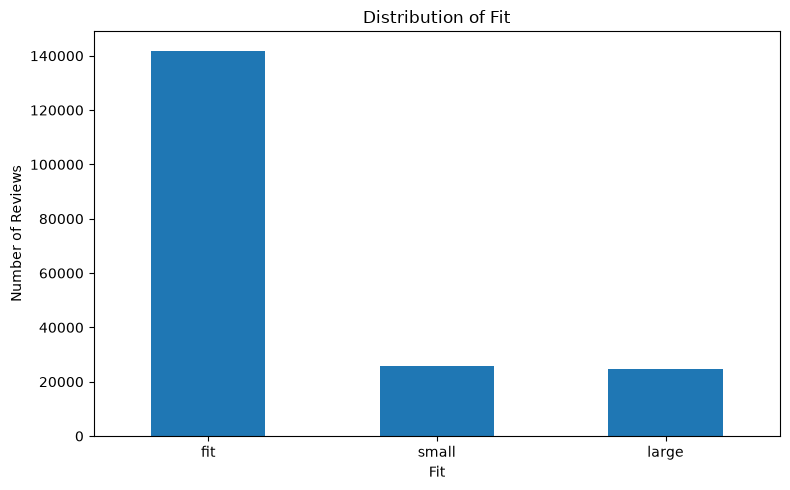

In [54]:
import matplotlib.pyplot as plt

fit_counts = df_clean["fit"].value_counts()

fit_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Fit")
plt.xlabel("Fit")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

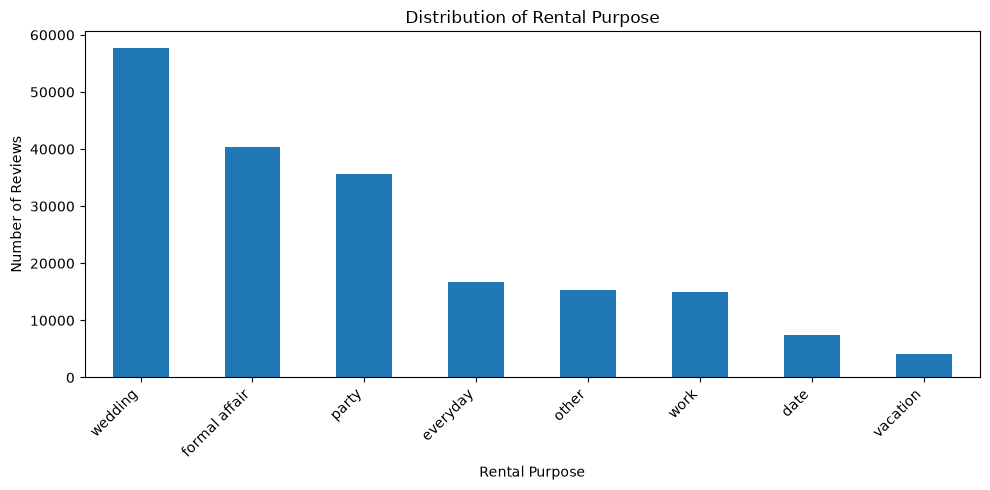

In [55]:
rental_counts = df_clean["rented for"].value_counts()

rental_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribution of Rental Purpose")
plt.xlabel("Rental Purpose")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

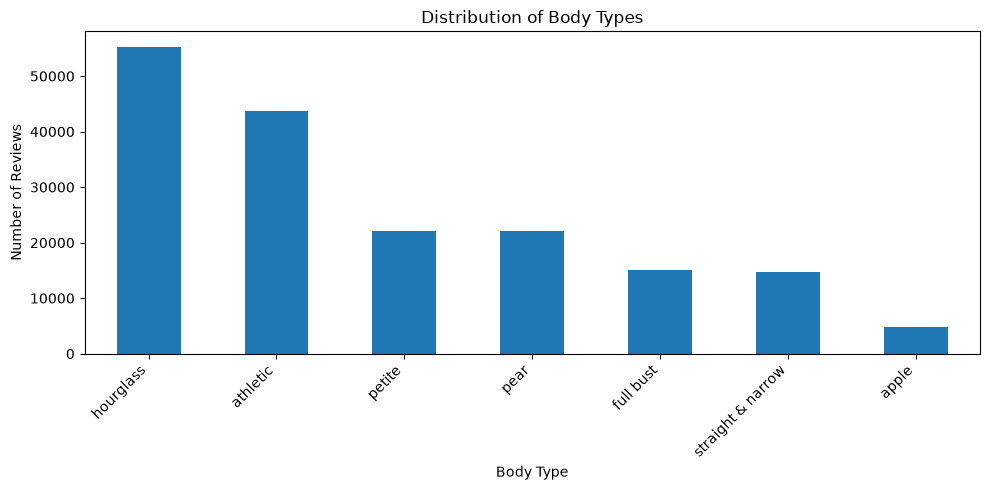

In [56]:
body_type_counts = (
    df_clean["body type"]
    .value_counts()
    .dropna()
)

body_type_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribution of Body Types")
plt.xlabel("Body Type")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [57]:
rating_counts = df_clean["rating"].value_counts().sort_index()

print(rating_counts)

rating
2.0       1046
4.0       2787
6.0      10688
8.0      53340
10.0    124413
Name: count, dtype: int64


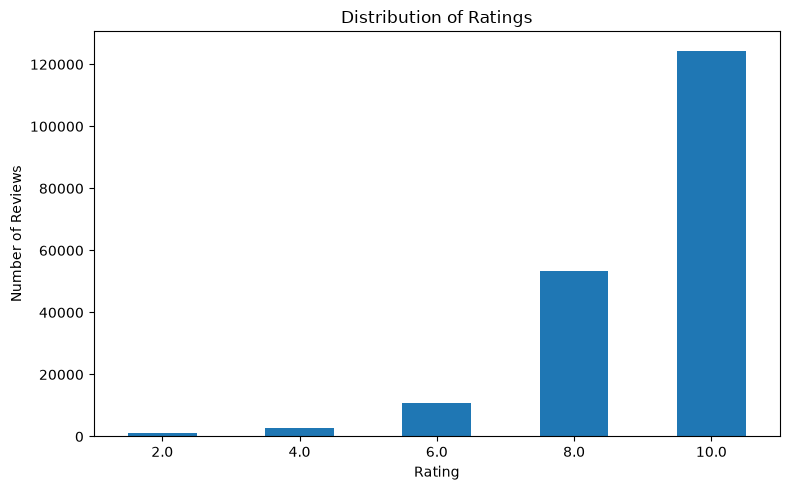

In [58]:
rating_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [59]:
average_rating = df_clean["rating"].mean()

print("Average Rating:", average_rating)

Average Rating: 9.092326575616047


In [60]:
average_rating_5 = df_clean["rating"].mean() / 2

print("Average Rating (1–5 scale):", average_rating_5)

Average Rating (1–5 scale): 4.546163287808024


In [61]:
fit_rating = (
    df_clean.groupby("fit")["rating"]
    .mean()
    .sort_values(ascending=False)
)

print(fit_rating)

fit
fit      9.308391
large    8.552018
small    8.419904
Name: rating, dtype: float64


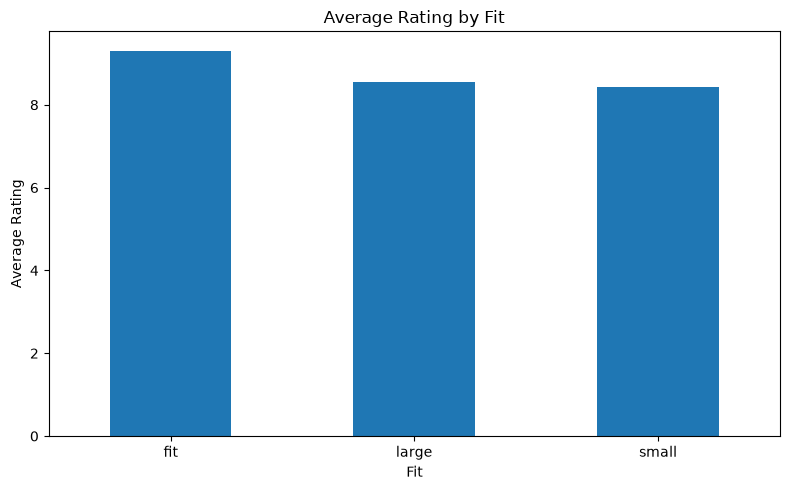

In [62]:
fit_rating.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Rating by Fit")
plt.xlabel("Fit")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [63]:
print(fit_rating)

fit
fit      9.308391
large    8.552018
small    8.419904
Name: rating, dtype: float64


In [64]:
rental_rating = (
    df_clean.groupby("rented for")["rating"]
    .mean()
    .sort_values(ascending=False)
)

print(rental_rating)

rented for
formal affair    9.210967
wedding          9.190139
other            9.115177
party            9.056009
vacation         8.980788
date             8.954884
work             8.851288
everyday         8.830815
Name: rating, dtype: float64


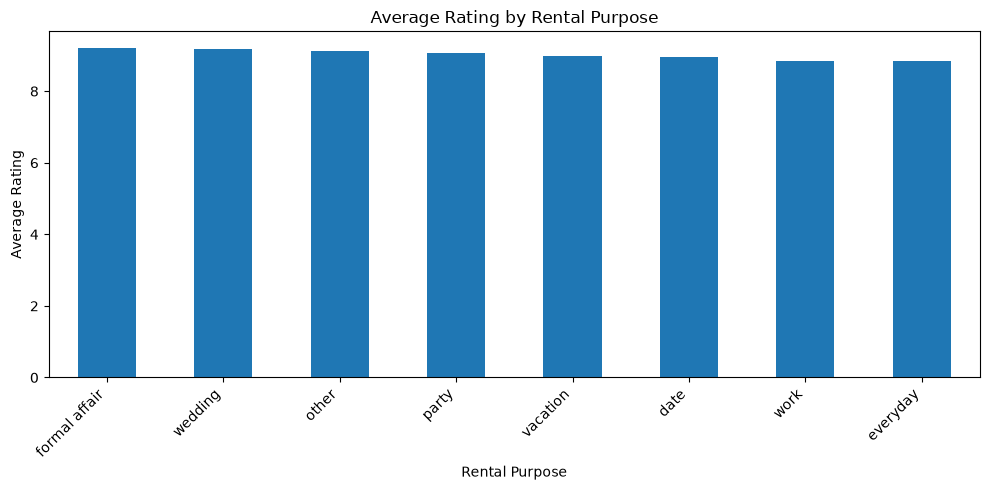

In [65]:
rental_rating.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Rating by Rental Purpose")
plt.xlabel("Rental Purpose")
plt.ylabel("Average Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [66]:
category_rating = (
    df_clean.groupby("category")["rating"]
    .agg(["mean", "count"])
)

category_rating = category_rating[
    category_rating["count"] >= 100
].sort_values(
    "mean",
    ascending=False
)

print(category_rating)

                mean  count
category                   
gown        9.272038  44332
leggings    9.267857    112
bomber      9.265625    128
down        9.176724    464
maxi        9.145513   3443
sheath      9.142650  19264
frock       9.141463    205
culottes    9.127660    188
print       9.106796    103
jacket      9.086522   2404
dress       9.051360  92718
jumpsuit    9.011188   5184
vest        9.007194    278
sweatshirt  8.992000    125
pant        8.990654    107
cardigan    8.962656    241
romper      8.949186   3070
skirt       8.948400   1531
shift       8.931742   5362
coat        8.930612    980
suit        8.926829    123
blazer      8.923274    782
shirtdress  8.891632    729
top         8.848915   4931
tank        8.806630    181
blouse      8.786482    651
shirt       8.779783    277
tunic       8.777778    162
sweater     8.743255   1149
mini        8.692176   1751
pants       8.677725    422


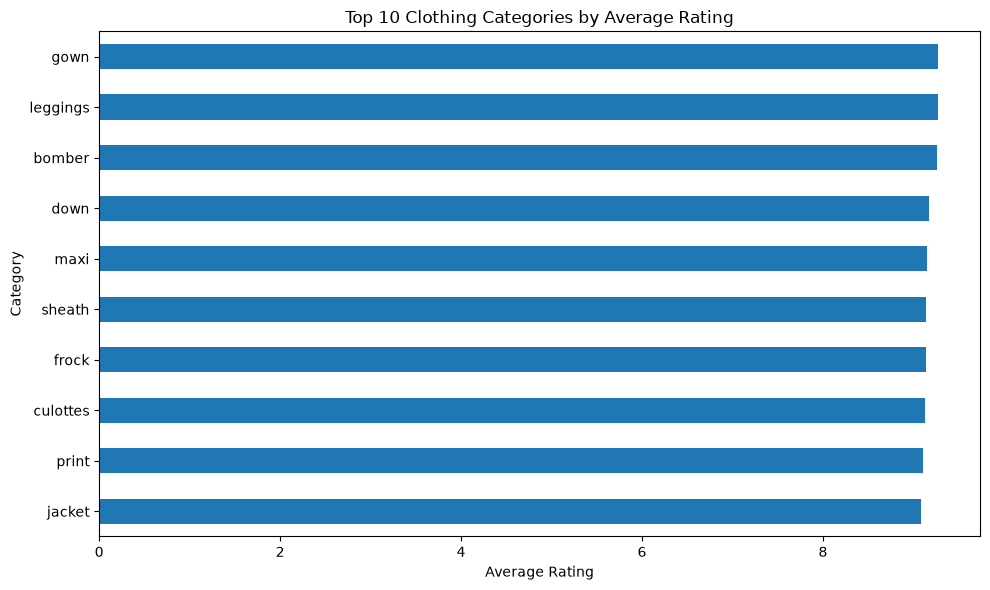

In [67]:
top_category_rating = category_rating.head(10)

top_category_rating["mean"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Clothing Categories by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [68]:
df_clean["category"].value_counts().head(20)

category
dress         92752
gown          44377
sheath        19264
shift          5364
jumpsuit       5184
top            4931
maxi           3443
romper         3070
jacket         2404
mini           1751
skirt          1531
sweater        1149
coat            980
blazer          782
shirtdress      729
blouse          651
down            464
pants           422
vest            278
shirt           277
Name: count, dtype: int64

In [69]:
print(category_rating.head(10))

              mean  count
category                 
gown      9.272038  44332
leggings  9.267857    112
bomber    9.265625    128
down      9.176724    464
maxi      9.145513   3443
sheath    9.142650  19264
frock     9.141463    205
culottes  9.127660    188
print     9.106796    103
jacket    9.086522   2404


In [70]:
df_clean["fit_problem"] = df_clean["fit"].isin(
    ["small", "large"]
)

In [71]:
fit_by_category = (
    df_clean.groupby("category")
    .agg(
        total_reviews=("fit", "count"),
        fit_problems=("fit_problem", "sum")
    )
)

fit_by_category["fit_problem_rate"] = (
    fit_by_category["fit_problems"]
    / fit_by_category["total_reviews"]
    * 100
)

fit_by_category = fit_by_category[
    fit_by_category["total_reviews"] >= 100
].sort_values(
    "fit_problem_rate",
    ascending=False
)

print(fit_by_category.head(15))

            total_reviews  fit_problems  fit_problem_rate
category                                                 
vest                  278           115         41.366906
coat                  980           396         40.408163
pants                 422           159         37.677725
shirt                 277           102         36.823105
tunic                 162            58         35.802469
cardigan              241            82         34.024896
shift                5364          1698         31.655481
skirt                1531           480         31.352057
frock                 205            64         31.219512
tank                  181            56         30.939227
culottes              188            58         30.851064
shirtdress            729           222         30.452675
sweatshirt            125            38         30.400000
down                  464           140         30.172414
jacket               2404           723         30.074875


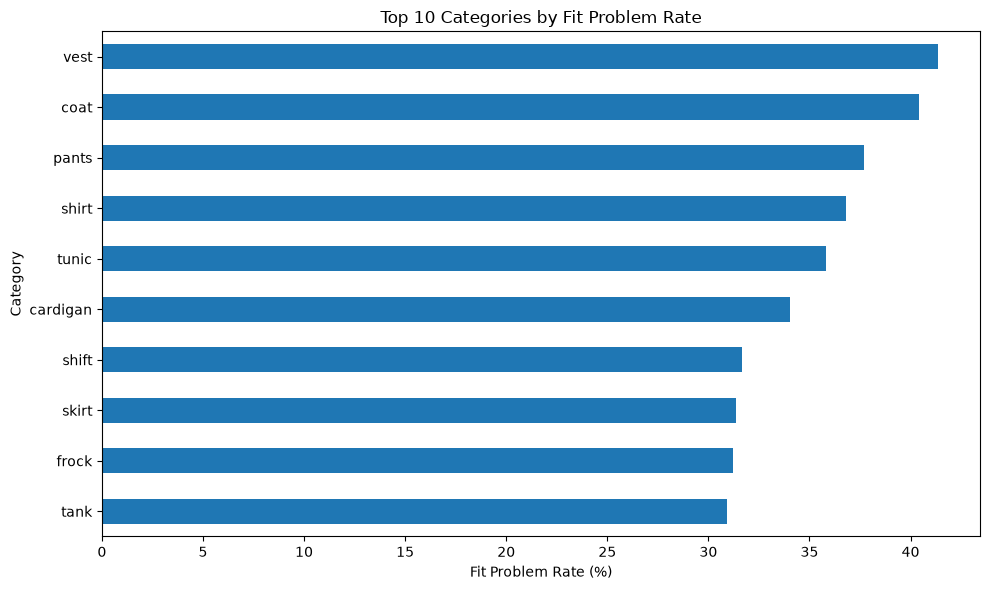

In [72]:
top_fit_problems = fit_by_category.head(10)

top_fit_problems["fit_problem_rate"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Categories by Fit Problem Rate")
plt.xlabel("Fit Problem Rate (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [73]:
fit_type_by_category = (
    df_clean.groupby(["category", "fit"])
    .size()
    .unstack(fill_value=0)
)

fit_type_by_category = fit_type_by_category[
    ["small", "large"]
]

fit_type_by_category["fit_problems"] = (
    fit_type_by_category["small"]
    + fit_type_by_category["large"]
)

fit_type_by_category = fit_type_by_category[
    fit_type_by_category["fit_problems"] >= 100
]

print(
    fit_type_by_category.sort_values(
        "fit_problems",
        ascending=False
    ).head(15)
)

fit         small  large  fit_problems
category                              
dress       13669  12627         26296
gown         4737   4465          9202
sheath       3118   1632          4750
shift         806    892          1698
top           521    802          1323
jumpsuit      672    646          1318
maxi          286    552           838
romper        343    479           822
jacket        362    361           723
skirt         266    214           480
mini          320    131           451
coat           36    360           396
sweater       110    221           331
shirtdress     51    171           222
blazer         70    117           187


In [74]:
fit_direction = fit_type_by_category.copy()

fit_direction["small_pct"] = (
    fit_direction["small"]
    / fit_direction["fit_problems"]
    * 100
)

fit_direction["large_pct"] = (
    fit_direction["large"]
    / fit_direction["fit_problems"]
    * 100
)

print(
    fit_direction.sort_values(
        "fit_problems",
        ascending=False
    ).head(15)
)

fit         small  large  fit_problems  small_pct  large_pct
category                                                    
dress       13669  12627         26296  51.981290  48.018710
gown         4737   4465          9202  51.477940  48.522060
sheath       3118   1632          4750  65.642105  34.357895
shift         806    892          1698  47.467609  52.532391
top           521    802          1323  39.380197  60.619803
jumpsuit      672    646          1318  50.986343  49.013657
maxi          286    552           838  34.128878  65.871122
romper        343    479           822  41.727494  58.272506
jacket        362    361           723  50.069156  49.930844
skirt         266    214           480  55.416667  44.583333
mini          320    131           451  70.953437  29.046563
coat           36    360           396   9.090909  90.909091
sweater       110    221           331  33.232628  66.767372
shirtdress     51    171           222  22.972973  77.027027
blazer         70    117

In [75]:
body_fit = pd.crosstab(
    df_clean["body type"],
    df_clean["fit"],
    normalize="index"
) * 100

print(body_fit.round(2))

fit                  fit  large  small
body type                             
apple              71.55  13.65  14.80
athletic           74.32  12.03  13.65
full bust          71.80  13.97  14.23
hourglass          73.81  13.01  13.19
pear               72.88  14.44  12.68
petite             74.32  13.08  12.60
straight & narrow  74.59  12.04  13.37


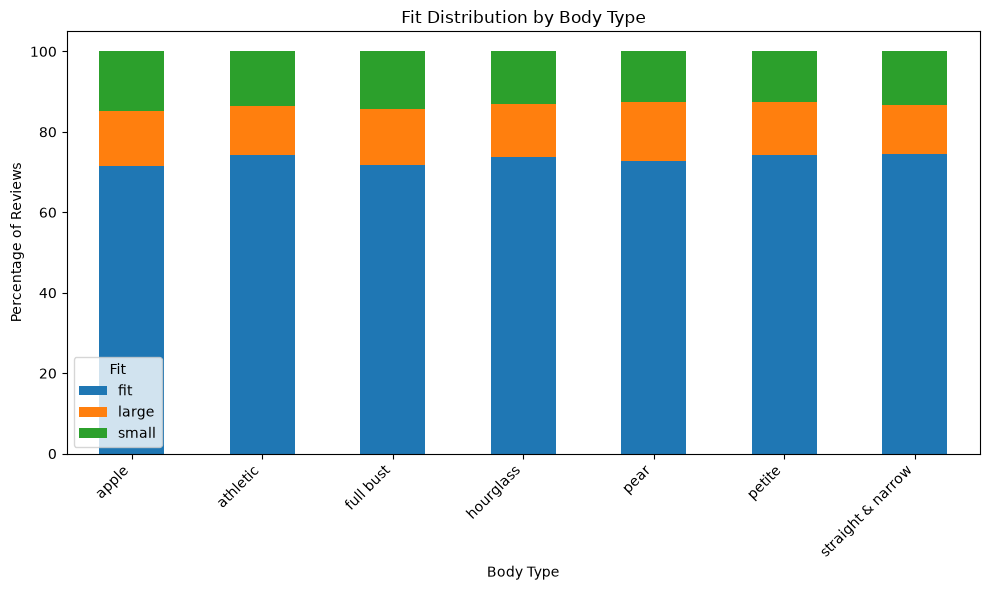

In [76]:
body_fit.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Fit Distribution by Body Type")
plt.xlabel("Body Type")
plt.ylabel("Percentage of Reviews")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Fit")
plt.tight_layout()
plt.show()

In [77]:
body_rating = (
    df_clean.groupby("body type")["rating"]
    .agg(["mean", "count"])
)

body_rating = body_rating[
    body_rating["count"] >= 100
].sort_values(
    "mean",
    ascending=False
)

print(body_rating)

                       mean  count
body type                         
straight & narrow  9.157158  14724
athletic           9.122019  43616
petite             9.079888  22106
hourglass          9.077828  55250
pear               9.040822  22096
full bust          9.022688  14986
apple              8.927941   4871


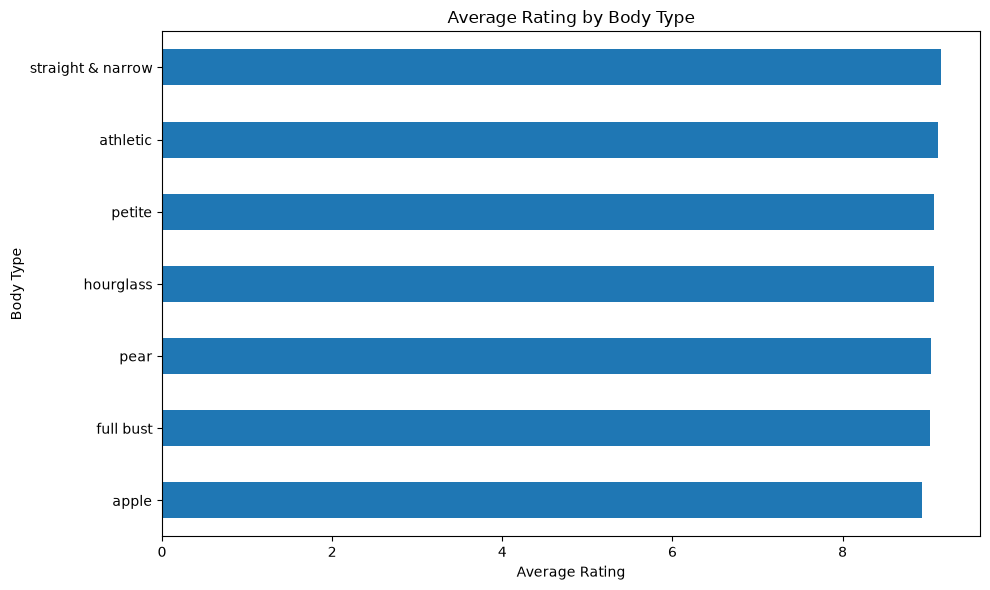

In [78]:
body_rating["mean"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Average Rating by Body Type")
plt.xlabel("Average Rating")
plt.ylabel("Body Type")
plt.tight_layout()
plt.show()

In [79]:
print(body_rating)

                       mean  count
body type                         
straight & narrow  9.157158  14724
athletic           9.122019  43616
petite             9.079888  22106
hourglass          9.077828  55250
pear               9.040822  22096
full bust          9.022688  14986
apple              8.927941   4871


In [80]:
bins = [17, 24, 34, 44, 54, 100]

labels = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55+"
]

df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=bins,
    labels=labels
)

print(df_clean["age_group"].value_counts().sort_index())

age_group
18-24     11322
25-34    110764
35-44     49045
45-54     15124
55+        4784
Name: count, dtype: int64


In [81]:
age_rating = (
    df_clean.groupby("age_group", observed=True)["rating"]
    .agg(["mean", "count"])
)

print(age_rating)

               mean   count
age_group                  
18-24      9.309059   11315
25-34      9.107455  110735
35-44      9.014689   49016
45-54      9.056971   15113
55+        9.107531    4780


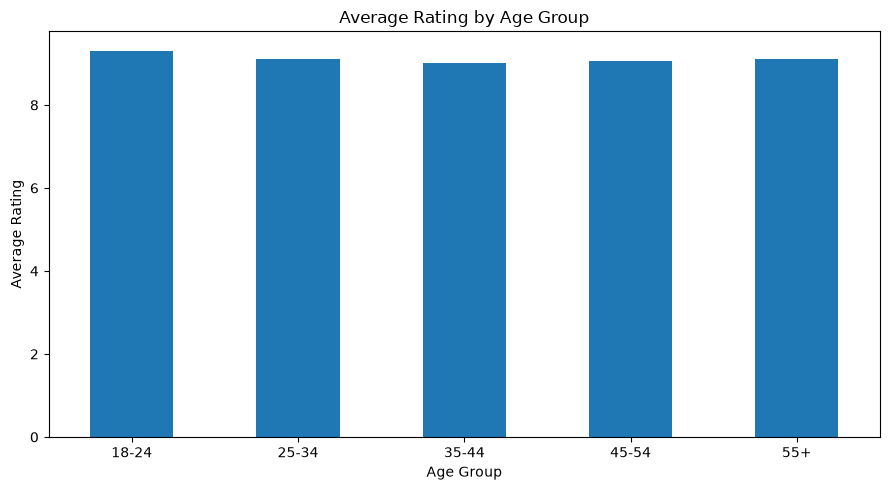

In [82]:
age_rating["mean"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Rating by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [83]:
print(age_rating)

               mean   count
age_group                  
18-24      9.309059   11315
25-34      9.107455  110735
35-44      9.014689   49016
45-54      9.056971   15113
55+        9.107531    4780


In [84]:
age_fit = pd.crosstab(
    df_clean["age_group"],
    df_clean["fit"],
    normalize="index"
) * 100

print(age_fit.round(2))

fit          fit  large  small
age_group                     
18-24      75.55  13.01  11.44
25-34      73.30  13.12  13.58
35-44      74.11  12.88  13.02
45-54      74.65  11.47  13.88
55+        74.00  10.33  15.68


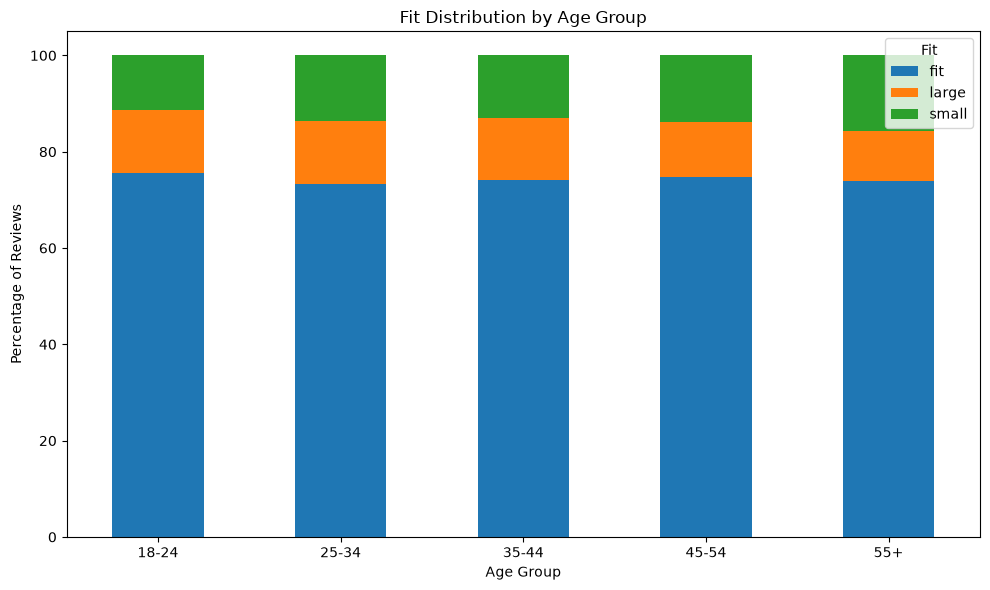

In [85]:
age_fit.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Fit Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Reviews")
plt.xticks(rotation=0)
plt.legend(title="Fit")
plt.tight_layout()
plt.show()

In [86]:
print(age_fit.round(2))

fit          fit  large  small
age_group                     
18-24      75.55  13.01  11.44
25-34      73.30  13.12  13.58
35-44      74.11  12.88  13.02
45-54      74.65  11.47  13.88
55+        74.00  10.33  15.68


# Dataset 5 — RentTheRunway Analysis Summary

## 1. Dataset Overview

The RentTheRunway dataset is a semi-structured JSON dataset containing clothing rental reviews and customer information.

- Original records: 192,544
- Columns: 15
- Unique users: 105,571
- Unique items: 5,850
- Exact duplicate rows: 189
- Records after removing exact duplicates: 192,355

The dataset contains customer information, clothing details, rental purposes, fit feedback, ratings, and review text.

---

## 2. Data Cleaning

### Duplicate Records

There were 189 exact duplicate rows.

These were removed using:

`df.drop_duplicates()`

The cleaned dataset contains 192,355 records.

### Missing Values

Important missing values were retained instead of deleting rows or artificially filling optional information.

The largest amount of missing data was found in:

- Weight: ~15.57%
- Bust size: ~9.56%
- Body type: ~7.60%
- Age: ~0.50%
- Height: ~0.35%
- Rating: ~0.04%

### Rating

The original rating values were stored as strings and were converted to numeric values.

The dataset uses a 10-point scale with ratings:

- 2
- 4
- 6
- 8
- 10

The overall average rating was approximately:

**9.09 / 10**

Equivalent to approximately:

**4.55 / 5**

The distribution is strongly concentrated toward high ratings, with 10 being the most common rating.

### Age

Age was converted to numeric values.

Values below 18 and above 100 were considered invalid and converted to missing values while retaining the corresponding records.

A total of 356 invalid age values were identified.

### Height

Height values such as `5' 8"` were converted into centimeters.

A new `height_cm` column was created.

Average height was approximately:

**165.89 cm**

### Weight

Weight values such as `137lbs` were converted into kilograms.

A new `weight_kg` column was created.

Average recorded weight was approximately:

**62.32 kg**

### Review Date

Review dates were converted from text to datetime format.

The reviews range from:

**November 2010 to January 2018**

---

## 3. Fit Distribution

The most common fit result was:

- Fit: 141,909
- Small: 25,747
- Large: 24,699

The majority of rental reviews therefore reported that the clothing fit correctly.

---

## 4. Rental Purpose

The most common rental purposes were:

1. Wedding — 57,737
2. Formal affair — 40,380
3. Party — 35,578
4. Everyday — 16,810
5. Other — 15,366
6. Work — 15,029
7. Date — 7,382
8. Vacation — 4,062

Wedding rentals were the most common purpose in the dataset.

---

## 5. Body Type Distribution

The most common body types were:

1. Hourglass — 55,290
2. Athletic — 43,631
3. Petite — 22,113
4. Pear — 22,105
5. Full bust — 14,993
6. Straight & narrow — 14,727
7. Apple — 4,871

Body type information was missing for 14,625 records.

---

## 6. Clothing Categories

The dataset is dominated by dresses and formal clothing.

The most common categories included:

- Dress — 92,752
- Gown — 44,377
- Sheath — 19,264
- Shift — 5,364
- Jumpsuit — 5,184
- Top — 4,931
- Maxi — 3,443
- Romper — 3,070
- Jacket — 2,404
- Mini — 1,751

Dress and gown together account for a large proportion of the dataset.

---

## 7. Average Rating by Fit

Average ratings differed noticeably by fit result:

- Fit — 9.31
- Large — 8.55
- Small — 8.42

Reviews where the clothing fit correctly had the highest average rating.

This suggests that fit experience is associated with customer satisfaction.

---

## 8. Average Rating by Rental Purpose

Average ratings were:

- Formal affair — 9.21
- Wedding — 9.19
- Other — 9.12
- Party — 9.06
- Vacation — 8.98
- Date — 8.95
- Work — 8.85
- Everyday — 8.83

Formal-affair and wedding rentals had the highest average ratings, while everyday and work rentals had lower average ratings.

The differences are relatively small.

---

## 9. Category Rating Analysis

Among the highest-rated categories, examples included:

- Gown — 9.27
- Leggings — 9.27
- Bomber — 9.27
- Down — 9.18
- Maxi — 9.15
- Sheath — 9.14

Some categories have very small sample sizes, so average ratings for those categories should be interpreted carefully.

---

## 10. Fit Problems by Clothing Category

Fit problems were calculated as:

**Large + Small**

The categories with the highest fit-problem rates included:

- Vest — 41.37%
- Coat — 40.41%
- Pants — 37.68%
- Shirt — 36.82%
- Tunic — 35.80%
- Cardigan — 34.02%
- Shift — 31.66%
- Skirt — 31.35%
- Frock — 31.22%
- Tank — 30.94%

These categories may represent areas where sizing or garment fit is more challenging.

Categories with smaller numbers of reviews should be interpreted cautiously.

---

## 11. Fit Distribution by Clothing Category

The analysis also compared whether garments were more likely to be reported as small or large.

Examples:

- Coat: 9.09% small, 90.91% large
- Shirtdress: 22.97% small, 77.03% large
- Sweater: 33.23% small, 66.77% large
- Maxi: 34.13% small, 65.87% large
- Top: 39.38% small, 60.62% large
- Shift: 47.47% small, 52.53% large

This provides useful information about the direction of sizing problems, not just the overall fit-problem rate.

---

## 12. Body Type vs Fit

Correct-fit percentages by body type were:

- Straight & narrow — 74.59%
- Athletic — 74.32%
- Petite — 74.32%
- Hourglass — 73.81%
- Pear — 72.88%
- Full bust — 71.80%
- Apple — 71.55%

Apple and full-bust body types showed slightly higher proportions of fit problems.

However, the differences were relatively small, so body type should be considered associated with fit outcomes rather than a direct cause.

---

## 13. Body Type vs Rating

Average ratings by body type were:

- Straight & narrow — 9.157
- Athletic — 9.122
- Petite — 9.080
- Hourglass — 9.078
- Pear — 9.041
- Full bust — 9.023
- Apple — 8.928

The difference between the highest and lowest averages was approximately 0.23 points.

Therefore, body type is associated with some variation in ratings, but the overall difference is relatively small.

---

## 14. Age Group Distribution

Age groups were created to make demographic analysis easier:

- 18–24 — 11,322
- 25–34 — 110,764
- 35–44 — 49,045
- 45–54 — 15,124
- 55+ — 4,784

The 25–34 group represents the largest share of the dataset.

---

## 15. Age Group vs Rating

Average ratings were:

- 18–24 — 9.309
- 25–34 — 9.107
- 35–44 — 9.015
- 45–54 — 9.057
- 55+ — 9.108

The 18–24 group had the highest average rating, while the 35–44 group had the lowest.

The differences are relatively small, and the groups have very different sample sizes.

---

## 16. Age Group vs Fit

Correct-fit percentages were:

- 18–24 — 75.55%
- 25–34 — 73.30%
- 35–44 — 74.11%
- 45–54 — 74.65%
- 55+ — 74.00%

The 18–24 group had the highest correct-fit percentage.

The 55+ group had the highest proportion of items reported as small:

**15.68%**

Overall, fit outcomes were fairly similar across age groups.

---

# Key Business Insights

1. **Fit strongly relates to customer satisfaction.**
   Reviews reporting a correct fit had a considerably higher average rating than reviews reporting clothing as small or large.

2. **Wedding and formal-affair rentals dominate rental purposes.**
   This suggests that occasion-based clothing is an important part of the rental business.

3. **Dresses and gowns dominate the product categories.**
   This dataset is heavily concentrated around formal and occasion-based clothing.

4. **Some clothing categories have substantially higher fit-problem rates.**
   Vest, coat, pants, and shirt categories showed particularly high fit-problem percentages.

5. **Sizing problems can occur in different directions.**
   Some categories are much more frequently reported as large, while others have a more balanced distribution between small and large.

6. **Body type has a relatively small relationship with fit outcomes.**
   Most body types have correct-fit rates between approximately 71% and 75%.

7. **Age group has only a modest relationship with fit and rating.**
   The differences between age groups are relatively small compared with the overall dataset size.

8. **Overall customer ratings are highly positive.**
   The average rating of approximately 9.09/10 indicates generally positive customer experiences.

---

# Data Quality and Limitations

- The dataset contains substantial missing information for weight, bust size, and body type.
- Ratings are heavily concentrated toward 8 and 10.
- Some categories have relatively few observations, so their average ratings and fit rates may be unstable.
- Complaint-style interpretation should not be applied directly because these are rental reviews.
- Relationships observed in the data do not prove causation.
- The dataset covers reviews from approximately 2010–2018 and may not represent current rental behavior.
- Age, height, and weight were cleaned or transformed for analysis, but the original columns were retained.

In [87]:
sql_df = df_clean[
    [
        "user_id",
        "item_id",
        "fit",
        "rating",
        "rented for",
        "body type",
        "category",
        "age",
        "height_cm",
        "weight_kg",
        "review_date"
    ]
].copy()

sql_df.to_csv(
    "../03_Semi Structured Files/RentTheRunway_SQL.csv",
    index=False
)

In [88]:
sql_df.shape

(192355, 11)

In [90]:
sql_df.head()

,user_id,item_id,fit,rating,rented for,body type,category,age,height_cm,weight_kg,review_date
0,420272,2260466,fit,10.0,vacation,hourglass,romper,28.0,172.72,62.142104,2016-04-20
1,273551,153475,fit,10.0,other,straight & narrow,gown,36.0,167.64,59.874144,2013-06-18
2,360448,1063761,fit,10.0,party,NaN,sheath,NaN,162.56,NaN,2015-12-14
3,909926,126335,fit,8.0,formal affair,pear,dress,34.0,165.10,61.234920,2014-02-12
4,151944,616682,fit,10.0,wedding,athletic,gown,27.0,175.26,65.770840,2016-09-26
